In [1]:
import os
import numpy as np
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pynwb

In [2]:
regen = False

if regen:
	path = './data/2025-worm-fieseler/allworms/exported_data_gcamp_freely_moving/'

	signals_original = list()
	os.makedirs('../data/2025-worm-fieseler/allworms/ndarray', exist_ok=True)
	filenames = os.listdir(path)
	for i, filename in enumerate(filenames):
		nwbfile = pynwb.read_nwb(path + filename)
		#behavioral_data = nwbfile.processing['Behavior'].data_interfaces
		calcium_data = nwbfile.processing['CalciumActivity'].data_interfaces
		signal = np.array(calcium_data['SignalDFoF'].roi_response_series['SignalCalciumImResponseSeries'].data)
		signals_original.append(signal)
		np.save(f'../data/2025-worm-fieseler/allworms/ndarray/{filename}.npy', signal)

else:
	path = '../data/2025-worm-fieseler/allworms/ndarray'
	filenames = os.listdir(path)
	signals_original = list()
	for filename in filenames:
		signals_original.append(np.load(f'../data/2025-worm-fieseler/allworms/ndarray/{filename}'))

In [3]:
signals_scaled = list()
for i, signal in enumerate(signals_original):
	scaler = StandardScaler()
	signal_scaled = scaler.fit_transform(signal)
	signals_scaled.append(signal_scaled)

In [4]:
signals_reduced = list()
for i, signal in enumerate(signals_scaled):
	pca = PCA(n_components=2)
	signal_reduced = pca.fit_transform(signal)
	signals_reduced.append(signal_reduced)

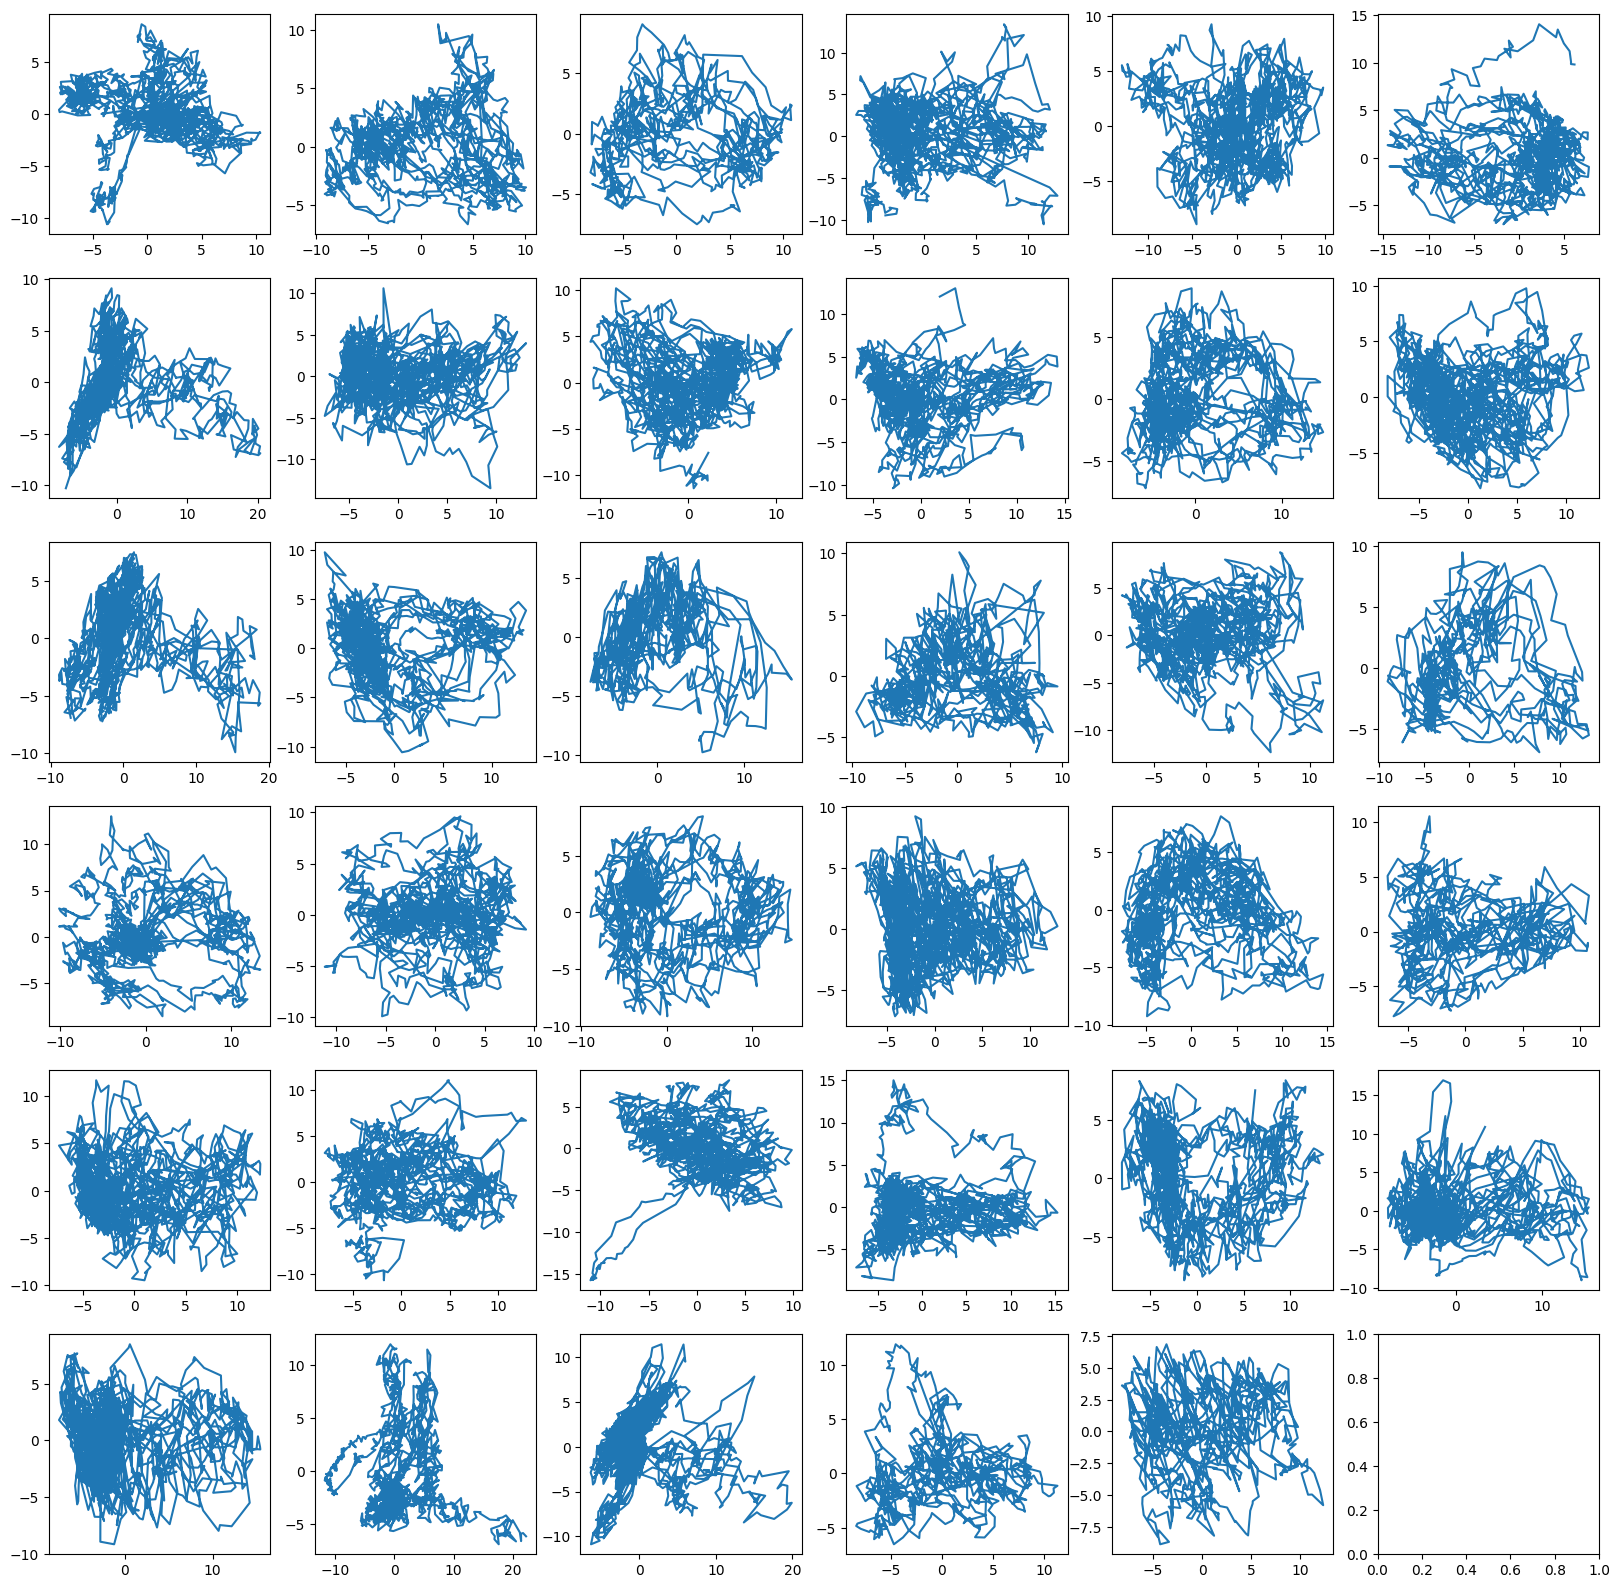

In [5]:
fig, axes = plt.subplots(6, 6, figsize=(20, 20))
for i, signal in enumerate(signals_reduced):
	axes[i // 6, i % 6].plot(signal[:, 0], signal[:, 1])

In [6]:
signals_pp = list()
for i, signal in enumerate(signals_reduced):
	if len(signal) > 1167:
		signals_pp.append(signal[:1167])
	if len(signal) == 1166:
		signals_pp.append(signal + np.empty(signal[0].shape))
	if len(signal) < 1166:
		continue

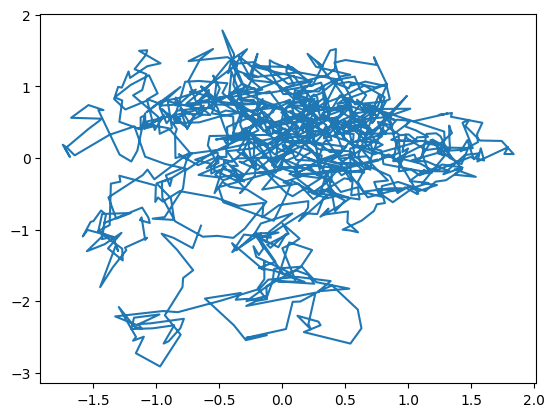

In [7]:
mean = np.mean(np.array(signals_pp), axis=0)
plt.plot(mean[:, 0], mean[:, 1])

In [16]:
signals_orig_pp = list()
for i, signal in enumerate(signals_original):
	if len(signal) > 1167:
		signals_orig_pp.append(signal[:1167])
	if len(signal) == 1166:
		signals_orig_pp.append(signal + np.empty(signal[0].shape))
	if len(signal) < 1166:
		continue

signal_concat = np.empty((1, 148))
for signal in signals_orig_pp:
	signal_concat = np.concatenate([signal_concat, signal[:, :148]])

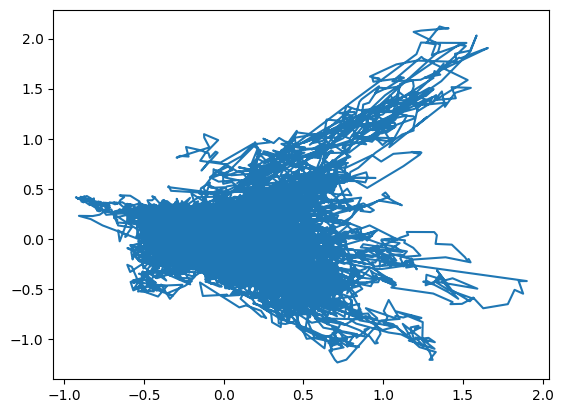

In [17]:
pca_all = PCA(n_components=2)
sigall = pca_all.fit_transform(signal_concat)
plt.plot(sigall[:, 0], sigall[:, 1])